# Ransomware & Network Intrusion Detection (UGRansome)

Classifies network-traffic records into three classes using machine learning:

| Label | Meaning |
|-------|---------|
| **A** | Anomaly: a zero-day / previously unseen attack pattern |
| **S** | Signature: matches a known attack signature |
| **SS** | Synthetic signature: a synthetic variant of a known signature |

**Dataset:** [UGRansome](https://www.kaggle.com/datasets/nkongolo/ugransome-dataset) has 149,043 records with protocol, TCP flags, ransomware family, Bitcoin payment amounts, netflow bytes, threat type and port.

**Notebook outline**
1. Explore the data
2. Build a leak-free pipeline (split first, fit encoders on training data only)
3. Compare 9 classifiers
4. Evaluate the best model
5. Stress-test with a *blocked* cross-validation, because neighbouring rows are near-duplicates
6. Explain the model with permutation feature importance

In [1]:
import json
import time
from pathlib import Path

import joblib
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
import sklearn
from sklearn.compose import ColumnTransformer
from sklearn.ensemble import (AdaBoostClassifier, BaggingClassifier, ExtraTreesClassifier,
                              HistGradientBoostingClassifier, RandomForestClassifier)
from sklearn.inspection import permutation_importance
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (accuracy_score, balanced_accuracy_score, classification_report,
                             confusion_matrix, f1_score)
from sklearn.model_selection import GroupKFold, train_test_split
from sklearn.naive_bayes import GaussianNB
from sklearn.neighbors import KNeighborsClassifier
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import OneHotEncoder, OrdinalEncoder, StandardScaler
from sklearn.tree import DecisionTreeClassifier

SEED = 42
DATA = Path("data/ugransome.csv")
SHOTS = Path("screenshots"); SHOTS.mkdir(exist_ok=True)
MODEL_DIR = Path("model"); MODEL_DIR.mkdir(exist_ok=True)
sns.set_style("whitegrid")
LABELS = {"A": "Anomaly", "S": "Signature", "SS": "Synthetic signature"}
PALETTE = {"A": "#ef4444", "S": "#3b82f6", "SS": "#f59e0b"}
print("scikit-learn", sklearn.__version__)

scikit-learn 1.9.1


## 1. Explore the data

In [2]:
df = pd.read_csv(DATA).rename(columns={"Protcol": "Protocol", "SeddAddress": "SeedAddress"})
print(df.shape)
print("Missing values:", int(df.isna().sum().sum()))
df.head()

(149043, 14)
Missing values: 0


,Time,Protocol,Flag,Family,Clusters,SeedAddress,ExpAddress,BTC,USD,Netflow_Bytes,IPaddress,Threats,Port,Prediction
0,50,TCP,A,WannaCry,1,1DA11mPS,1BonuSr7,1,500,5,A,Bonet,5061,SS
1,40,TCP,A,WannaCry,1,1DA11mPS,1BonuSr7,1,504,8,A,Bonet,5061,SS
2,30,TCP,A,WannaCry,1,1DA11mPS,1BonuSr7,1,508,7,A,Bonet,5061,SS
3,20,TCP,A,WannaCry,1,1DA11mPS,1BonuSr7,1,512,15,A,Bonet,5061,SS
4,57,TCP,A,WannaCry,1,1DA11mPS,1BonuSr7,1,516,9,A,Bonet,5061,SS


In [3]:
TARGET = "Prediction"
CATEGORICAL = df.drop(columns=TARGET).select_dtypes(exclude="number").columns.tolist()
NUMERIC = df.drop(columns=TARGET).select_dtypes(include="number").columns.tolist()
print("Categorical:", CATEGORICAL)
print("Numeric:    ", NUMERIC)
print()
print(df[TARGET].value_counts().rename(LABELS))

Categorical: ['Protocol', 'Flag', 'Family', 'SeedAddress', 'ExpAddress', 'IPaddress', 'Threats']
Numeric:     ['Time', 'Clusters', 'BTC', 'USD', 'Netflow_Bytes', 'Port']

Prediction
Signature              66380
Anomaly                42561
Synthetic signature    40102
Name: count, dtype: int64


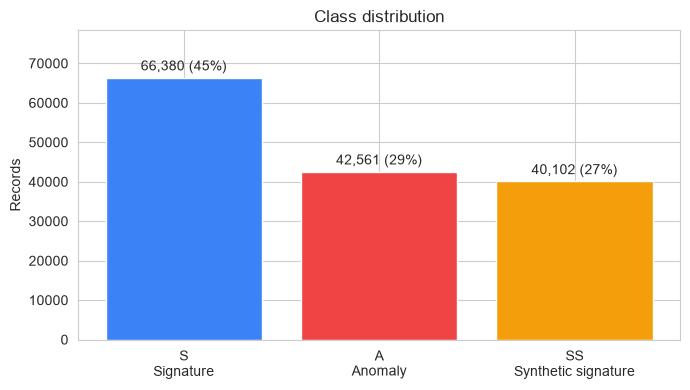

In [4]:
fig, ax = plt.subplots(figsize=(7, 4))
counts = df[TARGET].value_counts()
bars = ax.bar([f"{k}\n{LABELS[k]}" for k in counts.index], counts.values, color=[PALETTE[k] for k in counts.index])
ax.bar_label(bars, labels=[f"{v:,} ({v / len(df):.0%})" for v in counts.values], padding=3)
ax.set_ylim(0, counts.max() * 1.18); ax.set_ylabel("Records")
ax.set_title("Class distribution")
plt.tight_layout(); plt.savefig(SHOTS / "class_distribution.png", dpi=110); plt.show()

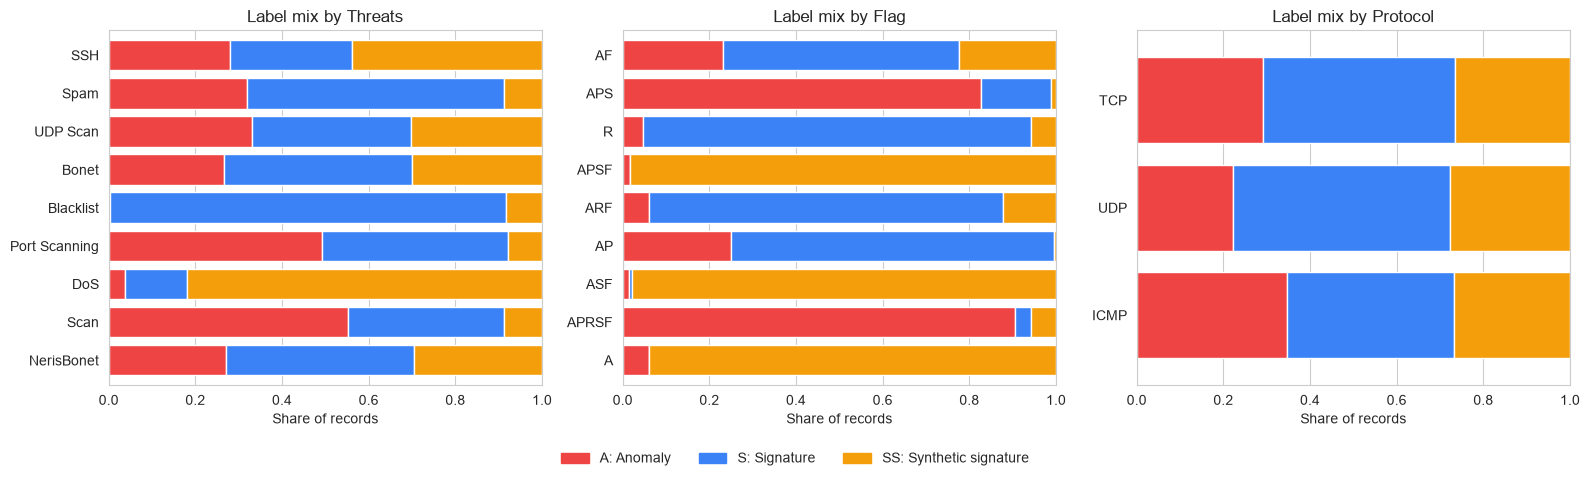

In [5]:
fig, axes = plt.subplots(1, 3, figsize=(16, 4.8))
for ax, col in zip(axes, ["Threats", "Flag", "Protocol"]):
    ct = pd.crosstab(df[col], df[TARGET], normalize="index")[["A", "S", "SS"]]
    ct = ct.loc[df[col].value_counts().index]
    ct.plot(kind="barh", stacked=True, ax=ax, color=[PALETTE[c] for c in ct.columns], width=0.8, legend=False)
    ax.set_title(f"Label mix by {col}"); ax.set_xlabel("Share of records"); ax.set_ylabel("")
    ax.invert_yaxis(); ax.set_xlim(0, 1)
handles = [plt.Rectangle((0, 0), 1, 1, color=PALETTE[k]) for k in ["A", "S", "SS"]]
fig.legend(handles, [f"{k}: {v}" for k, v in LABELS.items()], loc="lower center", ncol=3, frameon=False)
plt.tight_layout(rect=(0, 0.07, 1, 1)); plt.savefig(SHOTS / "label_mix_by_feature.png", dpi=110); plt.show()

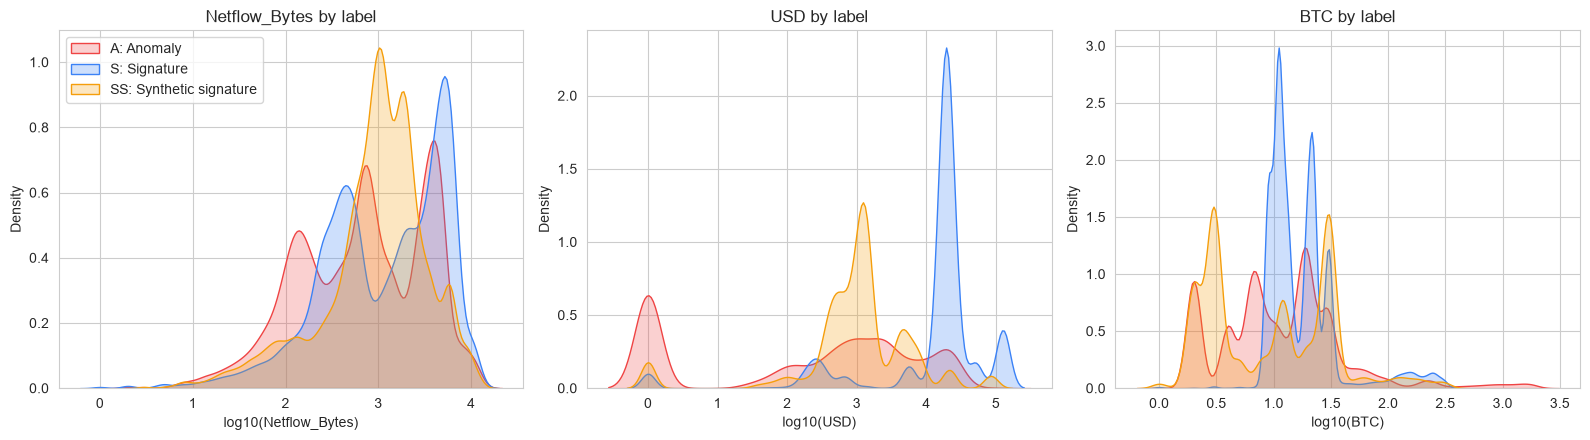

In [6]:
fig, axes = plt.subplots(1, 3, figsize=(16, 4.5))
for ax, col in zip(axes, ["Netflow_Bytes", "USD", "BTC"]):
    for lab in ["A", "S", "SS"]:
        sns.kdeplot(np.log10(df.loc[df[TARGET] == lab, col]), ax=ax, color=PALETTE[lab], fill=True, alpha=0.25,
                    label=f"{lab}: {LABELS[lab]}", warn_singular=False)
    ax.set_title(f"{col} by label"); ax.set_xlabel(f"log10({col})")
axes[0].legend()
plt.tight_layout(); plt.savefig(SHOTS / "numeric_distributions.png", dpi=110); plt.show()

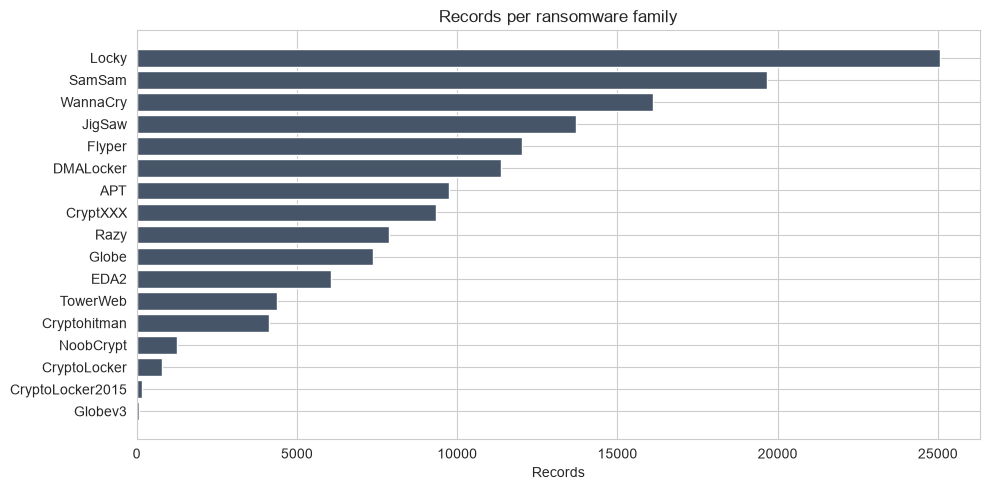

In [7]:
fam = df["Family"].value_counts()
fig, ax = plt.subplots(figsize=(10, 5))
ax.barh(fam.index[::-1], fam.values[::-1], color="#475569")
ax.set_title("Records per ransomware family"); ax.set_xlabel("Records")
plt.tight_layout(); plt.savefig(SHOTS / "ransomware_families.png", dpi=110); plt.show()

## 2. Leak-free preprocessing

- Split into train and test sets **first** (80/20, stratified).
- Encoders are fitted **inside a pipeline**, so they only ever see training data.
- No outlier removal: tree models are robust to extreme values, and in intrusion data the "outliers" (huge transfers, large ransom payments) are often the signal.

In [8]:
X, y = df.drop(columns=TARGET), df[TARGET]
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=SEED, stratify=y)
print("Train:", X_train.shape, " Test:", X_test.shape)

def tree_prep():
    return ColumnTransformer([("cat", OrdinalEncoder(handle_unknown="use_encoded_value", unknown_value=-1), CATEGORICAL)],
                             remainder="passthrough")

def linear_prep():
    return ColumnTransformer([("cat", OneHotEncoder(handle_unknown="ignore"), CATEGORICAL),
                              ("num", StandardScaler(), NUMERIC)])

Train: (119234, 13)  Test: (29809, 13)


## 3. Compare classifiers

In [9]:
models = {
    "Logistic Regression": make_pipeline(linear_prep(), LogisticRegression(max_iter=2000)),
    "Gaussian Naive Bayes": make_pipeline(linear_prep(), GaussianNB()),
    "k-Nearest Neighbours": make_pipeline(linear_prep(), KNeighborsClassifier(n_neighbors=5, n_jobs=-1)),
    "Decision Tree": make_pipeline(tree_prep(), DecisionTreeClassifier(random_state=SEED)),
    "AdaBoost": make_pipeline(tree_prep(), AdaBoostClassifier(random_state=SEED)),
    "Bagging (decision trees)": make_pipeline(tree_prep(), BaggingClassifier(random_state=SEED, n_jobs=-1)),
    "Random Forest": make_pipeline(tree_prep(), RandomForestClassifier(n_estimators=200, random_state=SEED, n_jobs=-1)),
    "Extra Trees": make_pipeline(tree_prep(), ExtraTreesClassifier(n_estimators=200, random_state=SEED, n_jobs=-1)),
    "Hist Gradient Boosting": make_pipeline(tree_prep(), HistGradientBoostingClassifier(max_iter=300, random_state=SEED)),
}
# GaussianNB needs dense input
models["Gaussian Naive Bayes"].steps[0][1].transformers[0][1].set_params(sparse_output=False)

rows, fitted = [], {}
for name, pipe in models.items():
    t = time.time(); pipe.fit(X_train, y_train); fit_s = time.time() - t
    pred = pipe.predict(X_test)
    rows.append({"Model": name, "Accuracy": accuracy_score(y_test, pred),
                 "Balanced accuracy": balanced_accuracy_score(y_test, pred),
                 "Macro F1": f1_score(y_test, pred, average="macro"), "Train time (s)": fit_s})
    fitted[name] = pipe
results = pd.DataFrame(rows).sort_values("Macro F1", ascending=False).reset_index(drop=True)
results.style.format({c: "{:.4f}" for c in ["Accuracy", "Balanced accuracy", "Macro F1"]} | {"Train time (s)": "{:.1f}"})

,Model,Accuracy,Balanced accuracy,Macro F1,Train time (s)
0,Hist Gradient Boosting,0.9942,0.9943,0.9943,12.5
1,Decision Tree,0.9938,0.9937,0.9938,2.0
2,Bagging (decision trees),0.9935,0.9935,0.9936,13.3
3,Random Forest,0.9932,0.9932,0.9932,16.4
4,Extra Trees,0.9922,0.9923,0.9923,15.6
5,k-Nearest Neighbours,0.9819,0.9820,0.9820,1.1
6,Logistic Regression,0.8830,0.8813,0.8799,11.3
7,AdaBoost,0.8799,0.8661,0.8720,32.3
8,Gaussian Naive Bayes,0.7957,0.8143,0.7949,1.6


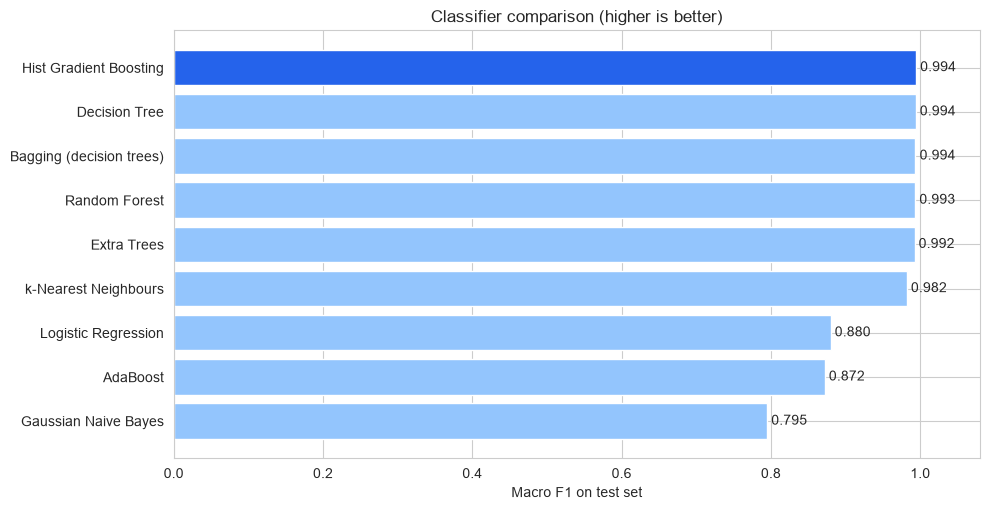

In [10]:
fig, ax = plt.subplots(figsize=(10, 5.2))
r = results.sort_values("Macro F1")
bars = ax.barh(r["Model"], r["Macro F1"], color=["#2563eb" if i == len(r) - 1 else "#93c5fd" for i in range(len(r))])
ax.bar_label(bars, labels=[f"{v:.3f}" for v in r["Macro F1"]], padding=3)
ax.set_xlim(0, 1.08); ax.set_xlabel("Macro F1 on test set")
ax.set_title("Classifier comparison (higher is better)")
plt.tight_layout(); plt.savefig(SHOTS / "model_comparison.png", dpi=110); plt.show()

## 4. Evaluate the best model

In [11]:
best_name = results.loc[0, "Model"]
best = fitted[best_name]
pred = best.predict(X_test)
print("Best model:", best_name)
print(classification_report(y_test, pred, target_names=[f"{k} ({v})" for k, v in LABELS.items()], digits=4))

Best model: Hist Gradient Boosting


                          precision    recall  f1-score   support

             A (Anomaly)     0.9928    0.9938    0.9933      8512
           S (Signature)     0.9941    0.9938    0.9940     13276
SS (Synthetic signature)     0.9959    0.9954    0.9956      8021

                accuracy                         0.9942     29809
               macro avg     0.9943    0.9943    0.9943     29809
            weighted avg     0.9942    0.9942    0.9942     29809



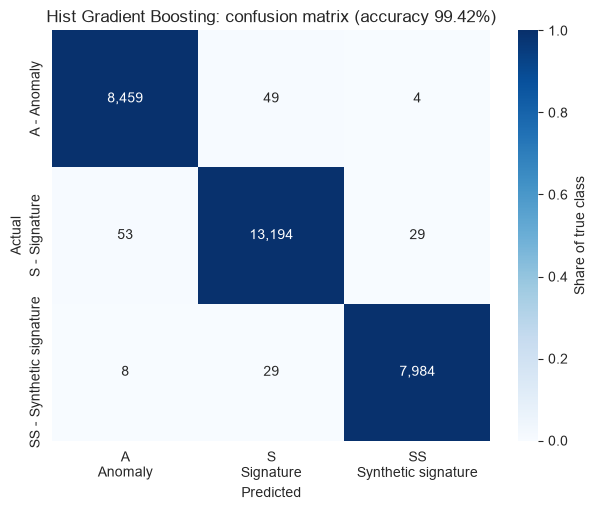

In [12]:
classes = ["A", "S", "SS"]
cm = confusion_matrix(y_test, pred, labels=classes)
plt.figure(figsize=(6.2, 5.2))
sns.heatmap(cm / cm.sum(axis=1, keepdims=True), annot=cm, fmt=",", cmap="Blues", vmin=0, vmax=1,
            xticklabels=[f"{c}\n{LABELS[c]}" for c in classes], yticklabels=[f"{c} - {LABELS[c]}" for c in classes],
            cbar_kws={"label": "Share of true class"})
plt.xlabel("Predicted"); plt.ylabel("Actual")
plt.title(f"{best_name}: confusion matrix (accuracy {accuracy_score(y_test, pred):.2%})")
plt.tight_layout(); plt.savefig(SHOTS / "confusion_matrix.png", dpi=110); plt.show()

## 5. Stress test: blocked cross-validation

UGRansome records are generated in sequence, so neighbouring rows are often near-identical (for example, the USD value increases by a fixed step). A random split can put a row in the test set while its near-twin sits in the training set, which flatters the score.

To check this, the data is cut into **contiguous blocks of 1,000 rows**, and whole blocks are held out with 5-fold `GroupKFold`. A model that only memorises neighbours would collapse here.

In [13]:
groups = np.arange(len(df)) // 1000
cv_rows = []
for name in results["Model"].head(3):
    scores = []
    for tr, te in GroupKFold(n_splits=5).split(X, y, groups):
        pipe = sklearn.clone(models[name]).fit(X.iloc[tr], y.iloc[tr])
        scores.append(accuracy_score(y.iloc[te], pipe.predict(X.iloc[te])))
    cv_rows.append({"Model": name, "Random split": results.set_index("Model").loc[name, "Accuracy"],
                    "Blocked CV mean": np.mean(scores), "Blocked CV std": np.std(scores),
                    "Blocked CV min": np.min(scores)})
    print(f"{name:<26} blocked CV accuracy {np.mean(scores):.4f} +/- {np.std(scores):.4f}  (folds: {np.round(scores, 4)})")
cv = pd.DataFrame(cv_rows)
cv

Hist Gradient Boosting     blocked CV accuracy 0.9791 +/- 0.0109  (folds: [0.9766 0.9793 0.9972 0.963  0.9792])


Decision Tree              blocked CV accuracy 0.9714 +/- 0.0162  (folds: [0.9761 0.9654 0.9958 0.946  0.9739])


Bagging (decision trees)   blocked CV accuracy 0.9731 +/- 0.0143  (folds: [0.9789 0.9614 0.9962 0.9552 0.9737])


,Model,Random split,Blocked CV mean,Blocked CV std,Blocked CV min
0,Hist Gradient Boosting,0.994230,0.979060,0.010869,0.963033
1,Decision Tree,0.993760,0.971447,0.016169,0.946000
2,Bagging (decision trees),0.993525,0.973086,0.014334,0.955200


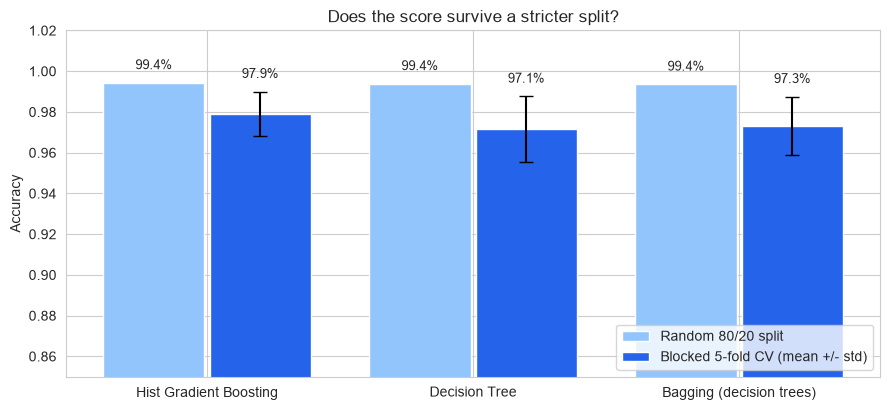

In [14]:
fig, ax = plt.subplots(figsize=(9, 4.2))
x = np.arange(len(cv))
b1 = ax.bar(x - 0.2, cv["Random split"], 0.38, label="Random 80/20 split", color="#93c5fd")
b2 = ax.bar(x + 0.2, cv["Blocked CV mean"], 0.38, yerr=cv["Blocked CV std"], capsize=5,
            label="Blocked 5-fold CV (mean +/- std)", color="#2563eb")
for bars in (b1, b2):
    ax.bar_label(bars, labels=[f"{v:.1%}" for v in bars.datavalues], padding=8, fontsize=9)
ax.set_xticks(x, cv["Model"]); ax.set_ylim(0.85, 1.02); ax.set_ylabel("Accuracy")
ax.legend(loc="lower right"); ax.set_title("Does the score survive a stricter split?")
plt.tight_layout(); plt.savefig(SHOTS / "blocked_cv.png", dpi=110); plt.show()

## 6. What drives the predictions? Permutation importance

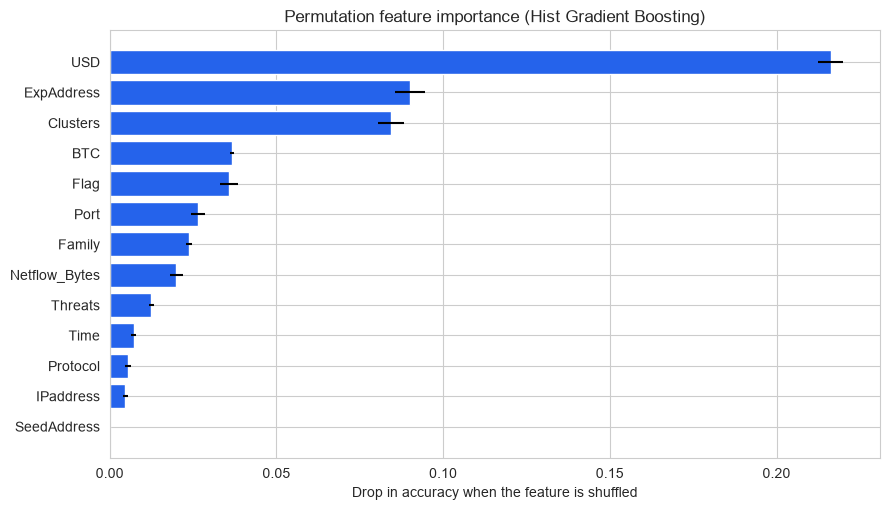

USD              0.2162
ExpAddress       0.0900
Clusters         0.0844
BTC              0.0368
Flag             0.0358
Port             0.0264
Family           0.0239
Netflow_Bytes    0.0200
Threats          0.0124
Time             0.0072
Protocol         0.0055
IPaddress        0.0047
SeedAddress      0.0002
dtype: float64

In [15]:
X_sample = X_test.sample(5000, random_state=SEED)
imp = permutation_importance(best, X_sample, y_test.loc[X_sample.index], n_repeats=5,
                             random_state=SEED, n_jobs=-1, scoring="accuracy")
importance = pd.Series(imp.importances_mean, index=X.columns).sort_values()
fig, ax = plt.subplots(figsize=(9, 5.2))
ax.barh(importance.index, importance.values, xerr=imp.importances_std[importance.index.map(list(X.columns).index)],
        color="#2563eb")
ax.set_xlabel("Drop in accuracy when the feature is shuffled")
ax.set_title(f"Permutation feature importance ({best_name})")
plt.tight_layout(); plt.savefig(SHOTS / "feature_importance.png", dpi=110); plt.show()
importance.sort_values(ascending=False).round(4)

## 7. Save the model

In [16]:
joblib.dump(best, MODEL_DIR / "intrusion_model.joblib", compress=3)
best_cv = cv.set_index("Model").loc[best_name] if best_name in set(cv["Model"]) else None
summary = {
    "model": best_name, "sklearn_version": sklearn.__version__,
    "test_accuracy": round(float(accuracy_score(y_test, pred)), 4),
    "test_balanced_accuracy": round(float(balanced_accuracy_score(y_test, pred)), 4),
    "test_macro_f1": round(float(f1_score(y_test, pred, average="macro")), 4),
    "blocked_cv_accuracy_mean": None if best_cv is None else round(float(best_cv["Blocked CV mean"]), 4),
    "blocked_cv_accuracy_std": None if best_cv is None else round(float(best_cv["Blocked CV std"]), 4),
    "features": list(X.columns),
}
(MODEL_DIR / "results.json").write_text(json.dumps(summary, indent=2))
results.round(4).to_csv(MODEL_DIR / "model_comparison.csv", index=False)
print(json.dumps(summary, indent=2))
print("Model file size: %.1f MB" % ((MODEL_DIR / "intrusion_model.joblib").stat().st_size / 1e6))

{
  "model": "Hist Gradient Boosting",
  "sklearn_version": "1.9.1",
  "test_accuracy": 0.9942,
  "test_balanced_accuracy": 0.9943,
  "test_macro_f1": 0.9943,
  "blocked_cv_accuracy_mean": 0.9791,
  "blocked_cv_accuracy_std": 0.0109,
  "features": [
    "Time",
    "Protocol",
    "Flag",
    "Family",
    "Clusters",
    "SeedAddress",
    "ExpAddress",
    "BTC",
    "USD",
    "Netflow_Bytes",
    "IPaddress",
    "Threats",
    "Port"
  ]
}
Model file size: 0.6 MB
